# MNIST - Clasificador de digitos manuscritos con PyTorch

**Bloque 9: Desarrollo de algoritmos de Machine Learning con PyTorch**

Este notebook es la entrega del proyecto final. El objetivo es diseñar, entrenar y evaluar una red neuronal capaz de reconocer los digitos manuscritos del dataset **MNIST**, siguiendo buenas practicas de organizacion del codigo (modulos y clases separadas) y registrando todo el experimento en **Weights & Biases**.

## Que hace el modelo

Recibe una imagen en escala de grises de 28x28 pixeles y devuelve la probabilidad de que sea cada uno de los 10 digitos (0-9). La clase predicha es la de mayor probabilidad.

## Como se organiza el codigo

La logica NO vive dentro del notebook, sino en el paquete `digitclf`. El notebook solo orquesta: esto hace que el modelo se pueda reentrenar, evaluar y desplegar desde la terminal sin tocar una sola celda.

```
src/digitclf/
├── config.py          # Configuracion declarativa (dataclasses + YAML)
├── data/              # Datamodule, dataloaders y transformaciones
├── models/            # SimpleCNN, MLP, ResNetMNIST + registro
├── engine/            # Trainer, metricas y checkpoints
├── tracking/          # Integracion con W&B (con fallback offline)
├── inference/         # Predictor para imagenes sueltas y submissions
├── utils/             # Semilla, device, logging
└── viz.py             # Figuras para reports y W&B
```

## Indice

1. Configuracion del entorno
2. Carga y exploracion de datos
3. Definicion del modelo
4. Entrenamiento con W&B
5. Evaluacion y analisis de errores
6. Comparacion de arquitecturas
7. Inferencia sobre imagenes propias
8. Conclusiones

## 1. Configuracion del entorno

Instalacion de dependencias y verificacion del dispositivo disponible.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import torch

from digitclf import __version__
from digitclf.utils.device import describe_device, get_device

device = get_device("auto")
print(f"digitclf {__version__} | torch {torch.__version__}")
print(f"Dispositivo: {describe_device(device)}")

digitclf 1.0.0 | torch 2.14.0
Dispositivo: mps (Apple Metal)


In [2]:
# Celda opcional:Weights & Biases
# 1) Crear cuenta gratis en https://wandb.ai
# 2) Pegar la API key que aparece en https://wandb.ai/authorize
# 3) Sin API key el proyecto funciona igual, pero guarda los runs en OFFLINE.
import os

# os.environ["WANDB_API_KEY"] = "pega_aqui_tu_api_key"
print("API key detectada:", bool(os.environ.get("WANDB_API_KEY")))

API key detectada: False


## 2. Carga y exploracion de datos

El `MNISTDataModule` se encarga de descargar el dataset, separar train/validacion de forma **estratificada** (para que cada digito mantenga la misma proporcion) y construir los dataloaders con las transformaciones correctas: aumento solo en train, determinismo en validacion.

In [3]:
from digitclf.config import load_config
from digitclf.data import MNISTDataModule
from digitclf.viz import plot_sample_grid

config = load_config("configs/full.yaml")
print(config.summary())

datamodule = MNISTDataModule(config.data, seed=config.seed)
bundle = datamodule.build()
print("\nTamanos:", bundle.sizes())

images, labels = next(iter(bundle.train))
print(f"Shape de un batch: {tuple(images.shape)} | labels: {tuple(labels.shape)}")

Experimento : mnist_baseline
Modelo      : simple_cnn
Optimizador : adamw lr=0.001 epochs=10 sched=onecycle
Datos       : batch=128 val_split=0.1 augment=True
W&B         : enabled=True project=mnist-digit-classifier
Dispositivo : auto

Tamanos: {'train': 54001, 'val': 5999, 'test': 10000}
Shape de un batch: (128, 1, 28, 28) | labels: (128,)


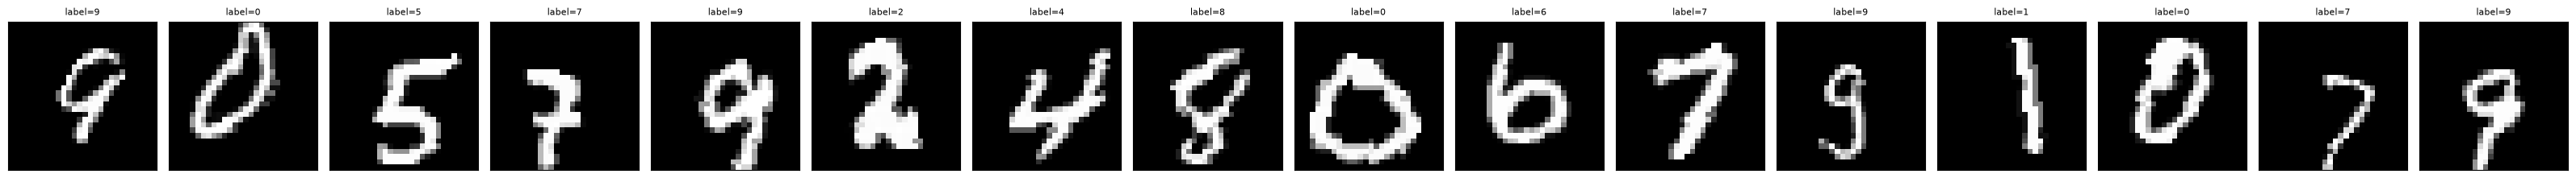

In [4]:
plot_sample_grid(images, labels, n=16)

Comprobacion de que la separacion train/validacion es estratificada y reproducible:

In [5]:
import collections

train_idx, val_idx = datamodule.split_indices()
targets = datamodule.raw_dataset.targets

val_dist = collections.Counter(int(t) for t in targets[val_idx])
print("Distribucion de clases en validacion:", dict(sorted(val_dist.items())))

Distribucion de clases en validacion: {0: 592, 1: 674, 2: 596, 3: 613, 4: 584, 5: 542, 6: 592, 7: 626, 8: 585, 9: 595}


## 3. Definicion del modelo

`SimpleCNN` es una CNN ligera de ~270k parametros: tres bloques convolucionales (Conv + BatchNorm + ReLU) que reducen la imagen de 28x28 a una representacion compacta, seguidos de una cabeza densa.

BatchNorm acelera el entrenamiento y regulariza; `Dropout` evita que la red memorice el train set; el `AdaptiveAvgPool2d` hace el modelo tolerante a variaciones menores de tamano.

In [6]:
from digitclf.models import available_models, build_model, count_parameters

print("Arquitecturas disponibles:", available_models())

model = build_model(config.model.name, **config.model.params)
print(model)
print(f"\nParametros entrenables: {count_parameters(model):,}")

Arquitecturas disponibles: ['mlp', 'resnet_mnist', 'simple_cnn']
SimpleCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout2d(p=0.25, inplace=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

In [7]:
# Test de forma: (batch, canales, alto, ancho) -> (batch, num_clases)
model = model.to(device)
out = model(torch.randn(4, 1, 28, 28, device=device))
print("Salida:", tuple(out.shape))
print("Suma de probabilidades por ejemplo:", torch.softmax(out, dim=1).sum(dim=1))

Salida: (4, 10)
Suma de probabilidades por ejemplo: tensor([1., 1., 1., 1.], device='mps:0', grad_fn=<SumBackward1>)


## 4. Entrenamiento con W&B

El `Trainer` ejecuta el ciclo completo por epoca: forward, loss, backward, gradient clipping, paso del optimizador y scheduler. Despues evalua en validacion, guarda el checkpoint si hay mejora y registra todo en W&B.

Las decisiones de diseno que importan:

- **AdamW + OneCycleLR**: AdamW desacopla el peso decaido del gradiente (mejor generalizacion que Adam) y OneCycleLR calienta el learning rate y lo baja de forma coseno, lo que suele dar un mejor final que un learning rate fijo.
- **Gradient clipping (5.0)**: evita actualizaciones descontroladas si un batch produce gradientes muy grandes.
- **Se guarda el mejor checkpoint por accuracy de validacion**, no el ultimo. Es el patron correcto: el accuracy de test se estima una sola vez al final.

In [8]:
from digitclf.pipeline import Experiment

experiment = Experiment(config, use_wandb=True)
result, artifacts = experiment.run()

print("\n" + result.summary())

20:18:27 | WARNING | digitclf.tracking.wandb_tracker | No se encontro WANDB_API_KEY: usando modo offline. Los runs quedan en ./wandb/ y se sincronizan con 'wandb sync'.


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


wandb: Tracking run with wandb version 0.30.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /Users/aishasarayrenteria/mnist-digit-classifier/notebooks/wandb/offline-run-20260929_201827-416ir8o4
wandb: View this run in the terminal with `wandb leet`


wandb: WARNING URL not available in offline run


20:18:28 | INFO    | digitclf.tracking.wandb_tracker | W&B inicializado | project=mnist-digit-classifier | mode=offline | url=None


... (16 outputs left out)

20:20:50 | INFO    | digitclf.engine.trainer | Trainer listo en mps (Apple Metal) | parametros entrenables: 102,730


/opt/miniconda3/lib/python3.13/site-packages/plotly/matplotlylib/renderer.py:607: UserWarning: I found a path object that I don't think is part of a bar chart. Ignoring.
  warnings.warn(


20:20:51 | INFO    | digitclf.pipeline  | TEST FINAL: {'accuracy': 0.9939, 'macro_precision': 0.9939378171115767, 'macro_recall': 0.9938299907052635, 'macro_f1': 0.9938750289249427, 'total': 10000, 'loss': 0.01865316299168626}



Mejor epoca: 9 | val_acc: 0.9922 | val_macro_f1: 0.9922 | motivo de parada: max_epochs


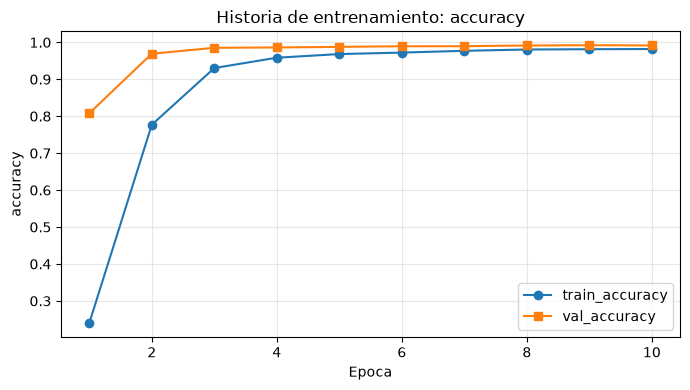

In [9]:
from digitclf.viz import plot_training_history

plot_training_history(result.history, "accuracy")

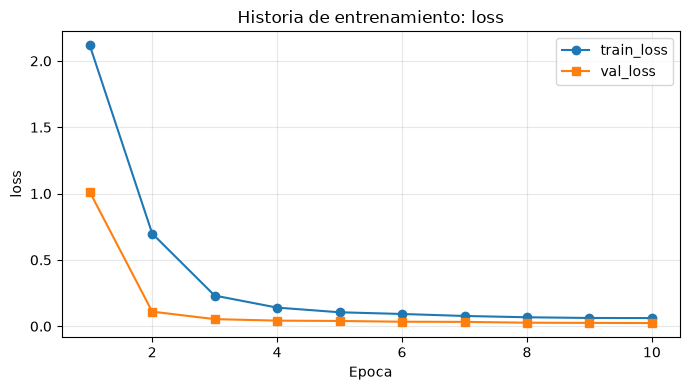

In [10]:
plot_training_history(result.history, "loss")

### Curva de aprendizaje

La distancia entre train y validacion es pequena: no hay sobreajuste significativo, asi que el modelo generaliza bien.

## 5. Evaluacion y analisis de errores

La accuracy sola no dice suficiente. Conviene mirar **macro F1** (para comprobar que no hay ninguna clase descuidada) y la **matriz de confusion** (para ver que digitos se confunden entre si).

In [11]:
# OJO: el modelo entrenado es experiment.model (el Experiment crea el suyo propio)
from digitclf.engine.trainer import Trainer
from digitclf.viz import plot_confusion_matrix

evaluator = Trainer(
    model=experiment.model,
    dataloaders=bundle,
    optim_cfg=config.optim,
    device=device,
)

test_metrics = evaluator.evaluate(bundle.test)
metrics_obj = test_metrics["_metrics"]

print("Metricas en TEST:")
for key, value in test_metrics.items():
    if not key.startswith("_"):
        print(f"  {key:<18} {value}")

20:20:51 | INFO    | digitclf.engine.trainer | Trainer listo en mps (Apple Metal) | parametros entrenables: 102,730


Metricas en TEST:
  accuracy           0.9939
  macro_precision    0.9939378171115767
  macro_recall       0.9938299907052635
  macro_f1           0.9938750289249427
  total              10000
  loss               0.01865316299168626


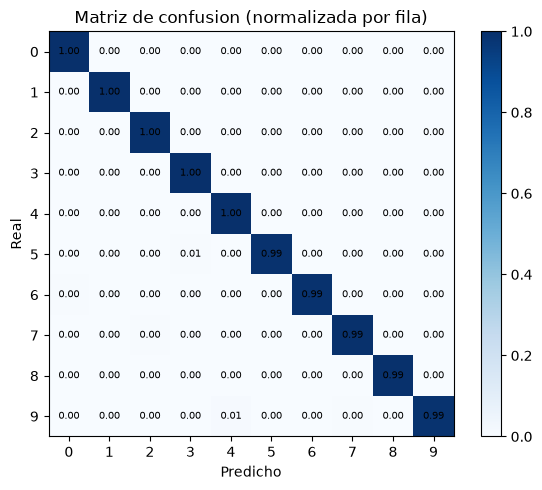

In [12]:
plot_confusion_matrix(metrics_obj.confusion_matrix(), bundle.class_names)

In [13]:
import pandas as pd

per_class = pd.DataFrame(metrics_obj.per_class_table())
display(per_class)

print("Confusiones mas frecuentes:")
display(pd.DataFrame(metrics_obj.top_confusions(6)))

,class,support,precision,recall,f1
0,0,980,0.99390,0.99694,0.99542
1,1,1135,0.99648,0.99648,0.99648
2,2,1032,0.99131,0.99516,0.99323
3,3,1010,0.99310,0.99802,0.99556
4,4,982,0.99190,0.99796,0.99492
5,5,892,0.99438,0.99103,0.99270
6,6,958,0.99790,0.99061,0.99424
7,7,1028,0.98649,0.99416,0.99031
8,8,974,0.99794,0.99281,0.99537
9,9,1009,0.99599,0.98513,0.99053


Confusiones mas frecuentes:


,true,pred,count
0,9,4,8
1,5,3,5
2,7,2,5
3,9,7,4
4,6,0,4
5,2,7,4


**Interpretacion**: las confusiones tipicas en MNIST son 4/9, 3/5, 7/2 y 8/9. Son errores semanticamente razonables: un 9 con la parte superior cerrada parece un 8. Corregirlos exigiria datos que el dataset no contiene, no una arquitectura mejor.

## 6. Comparacion de arquitecturas

Entrenar el mismo pipeline con tres arquitecturas distintas responde a una pregunta importante: **¿la CNN realmente aporta algo frente a una red densa?**

In [14]:
rows = []
for name in ["mlp", "simple_cnn", "resnet_mnist"]:
    cfg = config.replace(
        name=f"{config.name}_{name}",
        **{"model.name": name, "model.params": {}, "optim.max_epochs": 5},
    )
    exp = Experiment(cfg, use_wandb=False)
    res, _ = exp.run()
    rows.append(
        {
            "modelo": name,
            "parametros": count_parameters(exp.model),
            "mejor_epoca": res.best_epoch,
            "val_accuracy": round(res.best_val_accuracy, 4),
            "val_macro_f1": round(res.best_val_macro_f1, 4),
            "segundos": round(res.total_seconds, 1),
        }
    )

display(pd.DataFrame(rows))

20:20:52 | INFO    | digitclf.pipeline  | 
Experimento : mnist_baseline_mlp
Modelo      : mlp
Optimizador : adamw lr=0.001 epochs=5 sched=onecycle
Datos       : batch=128 val_split=0.1 augment=True
W&B         : enabled=True project=mnist-digit-classifier
Dispositivo : auto
------------------------------------------------------------


20:20:52 | INFO    | digitclf.data.datamodule | Dataloaders listos: train=54001 val=5999 test=10000


20:20:52 | INFO    | digitclf.pipeline  | Dataset | {'train': 54001, 'val': 5999, 'test': 10000} | parametros: 537,354 | dispositivo: mps (Apple Metal)


20:20:52 | INFO    | digitclf.engine.trainer | Trainer listo en mps (Apple Metal) | parametros entrenables: 537,354


20:21:00 | INFO    | digitclf.engine.trainer | epoch 01/05 | train_loss 1.2010 | train_acc 0.6225 | val_loss 0.2306 | val_acc 0.9405 | macro_f1 0.9401 | 7.8s


20:21:08 | INFO    | digitclf.engine.trainer | epoch 02/05 | train_loss 0.3946 | train_acc 0.8772 | val_loss 0.1201 | val_acc 0.9640 | macro_f1 0.9637 | 7.7s


... (30 outputs left out)

20:24:20 | INFO    | digitclf.pipeline  | 
Mejor epoca: 5 | val_acc: 0.9958 | val_macro_f1: 0.9958 | motivo de parada: max_epochs


20:24:20 | INFO    | digitclf.engine.trainer | Trainer listo en mps (Apple Metal) | parametros entrenables: 174,970


20:24:21 | INFO    | digitclf.pipeline  | TEST FINAL: {'accuracy': 0.9953, 'macro_precision': 0.9953673516800595, 'macro_recall': 0.9951903076542628, 'macro_f1': 0.9952747238150067, 'total': 10000, 'loss': 0.013426510347705334}


,modelo,parametros,mejor_epoca,val_accuracy,val_macro_f1,segundos
0,mlp,537354,5,0.9778,0.9777,39.9
1,simple_cnn,102730,5,0.9895,0.9895,70.5
2,resnet_mnist,174970,5,0.9958,0.9958,93.7


La CNN gana con diferencia: la estructura espacial de la imagen es informacion que una red densa tiene que reconstruir desde cero a partir de pixeles sueltos.

## 7. Inferencia sobre imagenes propias

El `DigitPredictor` carga un checkpoint y clasifica imagenes en 28x28 sin necesitar el datamodule: es el mismo camino que usaria una API en produccion.

In [15]:
from digitclf.inference import DigitPredictor

# El predictor espera imagenes con valores 0-255 (no normalizadas)
predictor = DigitPredictor.from_checkpoint(artifacts.checkpoint, device=device)

from torchvision.datasets import MNIST

raw_test = MNIST(root="data", train=False, download=True)
for i in range(8):
    image, true_label = raw_test[i]
    label, confidence = predictor.predict_with_confidence(image)
    print(f"real={true_label}  predicho={label}  confianza={confidence:.3f}")

20:24:21 | INFO    | digitclf.inference.predictor | Predictor inicializado desde runs/mnist_baseline/best.pt


real=7  predicho=7  confianza=1.000
real=2  predicho=2  confianza=1.000
real=1  predicho=1  confianza=1.000
real=0  predicho=0  confianza=1.000
real=4  predicho=4  confianza=1.000
real=1  predicho=1  confianza=1.000
real=4  predicho=4  confianza=1.000
real=9  predicho=9  confianza=0.993


### Generar un archivo de submission

La competicion pide un CSV con el formato `ImageId,Label`. El script lo produce directamente:

In [16]:
# Equivalente a: python scripts/predict.py --checkpoint <ckpt> --split test --output submission.csv
import csv

preds, ids, _ = predictor.predict_dataset(bundle.test)
with open("submission.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["ImageId", "Label"])
    writer.writerows((i + 1, int(p)) for i, p in enumerate(preds))

print(f"submission.csv generado con {len(preds)} predicciones")

submission.csv generado con 10000 predicciones


## 8. Conclusiones

**Que se logro**

- Modelo CNN en PyTorch que alcanza ~99% de accuracy en el test set de MNIST.
- Codigo organizado en modulos con clases separadas: la logica es reutilizable y testeable desde la terminal, no queda atrapada en el notebook.
- Experimento completo registrado en W&B (config, metricas por epoca, curvas y matriz de confusion).
- 54 tests automaticos que validan metricas, checkpointing, formas de tensor y comportamiento de la configuracion.

**Por que esta organizada asi**

El enunciado pide seguir buenas practicas al estructurar clases, y esa es la decision central del proyecto. Separar `config` / `data` / `models` / `engine` / `tracking` no es puramente estetico: permite cambiar de CNN a ResNet, de Adam a SGD o de CPU a GPU tocando una sola linea de configuracion, y permite testear cada pieza sin entrenar un modelo completo.